In [3]:
# Customer Churn Prediction Using Machine Learning

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix
)

from xgboost import XGBClassifier

import joblib
import shap

print("All libraries imported successfully!")


All libraries imported successfully!


In [4]:
# Customer Churn Prediction Using Machine Learning

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix
)

from xgboost import XGBClassifier

import joblib
import shap

print("All libraries imported successfully!")

All libraries imported successfully!


In [5]:
# Load the dataset

file_path = "../data/Telco_customer_churn.xlsx"

df = pd.read_excel(file_path)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

df.head()

Dataset loaded successfully!
Dataset shape: (7043, 33)


,CustomerID,Count,Country,State,City,Zip Code,Lat Long,Latitude,Longitude,Gender,...,Contract,Paperless Billing,Payment Method,Monthly Charges,Total Charges,Churn Label,Churn Value,Churn Score,CLTV,Churn Reason
0,3668-QPYBK,1,United States,California,Los Angeles,90003,"33.964131, -118.272783",33.964131,-118.272783,Male,...,Month-to-month,Yes,Mailed check,53.85,108.15,Yes,1,86,3239,Competitor made better offer
1,9237-HQITU,1,United States,California,Los Angeles,90005,"34.059281, -118.30742",34.059281,-118.307420,Female,...,Month-to-month,Yes,Electronic check,70.70,151.65,Yes,1,67,2701,Moved
2,9305-CDSKC,1,United States,California,Los Angeles,90006,"34.048013, -118.293953",34.048013,-118.293953,Female,...,Month-to-month,Yes,Electronic check,99.65,820.5,Yes,1,86,5372,Moved
3,7892-POOKP,1,United States,California,Los Angeles,90010,"34.062125, -118.315709",34.062125,-118.315709,Female,...,Month-to-month,Yes,Electronic check,104.80,3046.05,Yes,1,84,5003,Moved
4,0280-XJGEX,1,United States,California,Los Angeles,90015,"34.039224, -118.266293",34.039224,-118.266293,Male,...,Month-to-month,Yes,Bank transfer (automatic),103.70,5036.3,Yes,1,89,5340,Competitor had better devices


In [6]:
# Load the dataset

file_path = "../data/Telco_customer_churn.xlsx"

df = pd.read_excel(file_path)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

df.head()

Dataset loaded successfully!
Dataset shape: (7043, 33)


,CustomerID,Count,Country,State,City,Zip Code,Lat Long,Latitude,Longitude,Gender,...,Contract,Paperless Billing,Payment Method,Monthly Charges,Total Charges,Churn Label,Churn Value,Churn Score,CLTV,Churn Reason
0,3668-QPYBK,1,United States,California,Los Angeles,90003,"33.964131, -118.272783",33.964131,-118.272783,Male,...,Month-to-month,Yes,Mailed check,53.85,108.15,Yes,1,86,3239,Competitor made better offer
1,9237-HQITU,1,United States,California,Los Angeles,90005,"34.059281, -118.30742",34.059281,-118.307420,Female,...,Month-to-month,Yes,Electronic check,70.70,151.65,Yes,1,67,2701,Moved
2,9305-CDSKC,1,United States,California,Los Angeles,90006,"34.048013, -118.293953",34.048013,-118.293953,Female,...,Month-to-month,Yes,Electronic check,99.65,820.5,Yes,1,86,5372,Moved
3,7892-POOKP,1,United States,California,Los Angeles,90010,"34.062125, -118.315709",34.062125,-118.315709,Female,...,Month-to-month,Yes,Electronic check,104.80,3046.05,Yes,1,84,5003,Moved
4,0280-XJGEX,1,United States,California,Los Angeles,90015,"34.039224, -118.266293",34.039224,-118.266293,Male,...,Month-to-month,Yes,Bank transfer (automatic),103.70,5036.3,Yes,1,89,5340,Competitor had better devices


In [7]:
# Basic information about the dataset

print("Dataset Information")
print("===================")

print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

print("\nColumn names:")
print(df.columns.tolist())

print("\nData types:")
print(df.dtypes)

print("\nMissing values:")
print(df.isnull().sum())

Dataset Information
Number of rows: 7043
Number of columns: 33

Column names:
['CustomerID', 'Count', 'Country', 'State', 'City', 'Zip Code', 'Lat Long', 'Latitude', 'Longitude', 'Gender', 'Senior Citizen', 'Partner', 'Dependents', 'Tenure Months', 'Phone Service', 'Multiple Lines', 'Internet Service', 'Online Security', 'Online Backup', 'Device Protection', 'Tech Support', 'Streaming TV', 'Streaming Movies', 'Contract', 'Paperless Billing', 'Payment Method', 'Monthly Charges', 'Total Charges', 'Churn Label', 'Churn Value', 'Churn Score', 'CLTV', 'Churn Reason']

Data types:
CustomerID               str
Count                  int64
Country                  str
State                    str
City                     str
Zip Code               int64
Lat Long                 str
Latitude             float64
Longitude            float64
Gender                   str
Senior Citizen           str
Partner                  str
Dependents               str
Tenure Months          int64
Phone Servic

In [8]:
# Check the target variable

print("Churn Label Distribution")
print("=========================")

print(df["Churn Label"].value_counts())

print("\nChurn Percentage")
print("=================")

print(df["Churn Label"].value_counts(normalize=True) * 100)

Churn Label Distribution
Churn Label
No     5174
Yes    1869
Name: count, dtype: int64

Churn Percentage
Churn Label
No     73.463013
Yes    26.536987
Name: proportion, dtype: float64


In [9]:
# Create a separate dataset for machine learning

model_df = df[
    [
        "Gender",
        "Senior Citizen",
        "Partner",
        "Dependents",
        "Tenure Months",
        "Phone Service",
        "Multiple Lines",
        "Internet Service",
        "Online Security",
        "Online Backup",
        "Device Protection",
        "Tech Support",
        "Streaming TV",
        "Streaming Movies",
        "Contract",
        "Paperless Billing",
        "Payment Method",
        "Monthly Charges",
        "Total Charges",
        "Churn Label"
    ]
].copy()

print("Model dataset shape:", model_df.shape)

model_df.head()

Model dataset shape: (7043, 20)


,Gender,Senior Citizen,Partner,Dependents,Tenure Months,Phone Service,Multiple Lines,Internet Service,Online Security,Online Backup,Device Protection,Tech Support,Streaming TV,Streaming Movies,Contract,Paperless Billing,Payment Method,Monthly Charges,Total Charges,Churn Label
0,Male,No,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
1,Female,No,No,Yes,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes
2,Female,No,No,Yes,8,Yes,Yes,Fiber optic,No,No,Yes,No,Yes,Yes,Month-to-month,Yes,Electronic check,99.65,820.5,Yes
3,Female,No,Yes,Yes,28,Yes,Yes,Fiber optic,No,No,Yes,Yes,Yes,Yes,Month-to-month,Yes,Electronic check,104.80,3046.05,Yes
4,Male,No,No,Yes,49,Yes,Yes,Fiber optic,No,Yes,Yes,No,Yes,Yes,Month-to-month,Yes,Bank transfer (automatic),103.70,5036.3,Yes


In [10]:
# Convert Total Charges to numeric

model_df["Total Charges"] = pd.to_numeric(
    model_df["Total Charges"],
    errors="coerce"
)

print("Missing values after conversion:")
print(model_df.isnull().sum())

Missing values after conversion:
Gender                0
Senior Citizen        0
Partner               0
Dependents            0
Tenure Months         0
Phone Service         0
Multiple Lines        0
Internet Service      0
Online Security       0
Online Backup         0
Device Protection     0
Tech Support          0
Streaming TV          0
Streaming Movies      0
Contract              0
Paperless Billing     0
Payment Method        0
Monthly Charges       0
Total Charges        11
Churn Label           0
dtype: int64


In [11]:
# Fill missing Total Charges values with the median

median_total_charges = model_df["Total Charges"].median()

model_df["Total Charges"] = model_df["Total Charges"].fillna(
    median_total_charges
)

print("Median Total Charges:", median_total_charges)
print(
    "Remaining missing values in Total Charges:",
    model_df["Total Charges"].isnull().sum()
)

Median Total Charges: 1397.475
Remaining missing values in Total Charges: 0


In [12]:
# Separate input features and target variable

X = model_df.drop("Churn Label", axis=1)
y = model_df["Churn Label"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)

print("\nTarget values:")
print(y.value_counts())

Features shape: (7043, 19)
Target shape: (7043,)

Target values:
Churn Label
No     5174
Yes    1869
Name: count, dtype: int64


In [13]:
# Split the data into training and testing sets

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training data shape:", X_train.shape)
print("Testing data shape:", X_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts())

print("\nTesting target distribution:")
print(y_test.value_counts())

Training data shape: (5634, 19)
Testing data shape: (1409, 19)

Training target distribution:
Churn Label
No     4139
Yes    1495
Name: count, dtype: int64

Testing target distribution:
Churn Label
No     1035
Yes     374
Name: count, dtype: int64


In [14]:
# Identify categorical and numerical columns

categorical_cols = X_train.select_dtypes(
    include=["str", "object"]
).columns.tolist()

numerical_cols = X_train.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

print("Categorical columns:")
print(categorical_cols)

print("\nNumerical columns:")
print(numerical_cols)

print("\nNumber of categorical columns:", len(categorical_cols))
print("Number of numerical columns:", len(numerical_cols))

Categorical columns:
['Gender', 'Senior Citizen', 'Partner', 'Dependents', 'Phone Service', 'Multiple Lines', 'Internet Service', 'Online Security', 'Online Backup', 'Device Protection', 'Tech Support', 'Streaming TV', 'Streaming Movies', 'Contract', 'Paperless Billing', 'Payment Method']

Numerical columns:
['Tenure Months', 'Monthly Charges', 'Total Charges']

Number of categorical columns: 16
Number of numerical columns: 3


In [15]:
# Encode categorical variables and scale numerical variables

from sklearn.preprocessing import OneHotEncoder, StandardScaler

encoder = OneHotEncoder(
    handle_unknown="ignore",
    drop=None,
    sparse_output=False
)

scaler = StandardScaler()

X_train_cat = encoder.fit_transform(X_train[categorical_cols])
X_test_cat = encoder.transform(X_test[categorical_cols])

X_train_num = scaler.fit_transform(X_train[numerical_cols])
X_test_num = scaler.transform(X_test[numerical_cols])

X_train_processed = np.hstack([
    X_train_num,
    X_train_cat
])

X_test_processed = np.hstack([
    X_test_num,
    X_test_cat
])

print("Processed training shape:", X_train_processed.shape)
print("Processed testing shape:", X_test_processed.shape)

Processed training shape: (5634, 46)
Processed testing shape: (1409, 46)


In [16]:
# Encode target variable

y_train_encoded = y_train.map({
    "No": 0,
    "Yes": 1
})

y_test_encoded = y_test.map({
    "No": 0,
    "Yes": 1
})

print("Target encoding:")
print("No  = 0")
print("Yes = 1")

print("\nTraining target:")
print(y_train_encoded.value_counts())

print("\nTesting target:")
print(y_test_encoded.value_counts())

Target encoding:
No  = 0
Yes = 1

Training target:
Churn Label
0    4139
1    1495
Name: count, dtype: int64

Testing target:
Churn Label
0    1035
1     374
Name: count, dtype: int64


In [17]:
# Evaluate Logistic Regression

logistic_accuracy = accuracy_score(
    y_test_encoded,
    logistic_pred
)

logistic_precision = precision_score(
    y_test_encoded,
    logistic_pred
)

logistic_recall = recall_score(
    y_test_encoded,
    logistic_pred
)

logistic_f1 = f1_score(
    y_test_encoded,
    logistic_pred
)

logistic_roc_auc = roc_auc_score(
    y_test_encoded,
    logistic_prob
)

print("LOGISTIC REGRESSION")
print("===================")
print("Accuracy :", round(logistic_accuracy, 4))
print("Precision:", round(logistic_precision, 4))
print("Recall   :", round(logistic_recall, 4))
print("F1 Score :", round(logistic_f1, 4))
print("ROC-AUC  :", round(logistic_roc_auc, 4))

NameError: name 'logistic_pred' is not defined

In [18]:
# Evaluate Logistic Regression

logistic_accuracy = accuracy_score(
    y_test_encoded,
    logistic_pred
)

logistic_precision = precision_score(
    y_test_encoded,
    logistic_pred
)

logistic_recall = recall_score(
    y_test_encoded,
    logistic_pred
)

logistic_f1 = f1_score(
    y_test_encoded,
    logistic_pred
)

logistic_roc_auc = roc_auc_score(
    y_test_encoded,
    logistic_prob
)

print("LOGISTIC REGRESSION")
print("===================")
print("Accuracy :", round(logistic_accuracy, 4))
print("Precision:", round(logistic_precision, 4))
print("Recall   :", round(logistic_recall, 4))
print("F1 Score :", round(logistic_f1, 4))
print("ROC-AUC  :", round(logistic_roc_auc, 4))

NameError: name 'logistic_pred' is not defined

In [19]:
# Train Logistic Regression

logistic_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

logistic_model.fit(
    X_train_processed,
    y_train_encoded
)

logistic_pred = logistic_model.predict(
    X_test_processed
)

logistic_prob = logistic_model.predict_proba(
    X_test_processed
)[:, 1]

print("Logistic Regression trained successfully!")

Logistic Regression trained successfully!


In [20]:
# Train Random Forest

from sklearn.ensemble import RandomForestClassifier

random_forest_model = RandomForestClassifier(
    n_estimators=200,
    random_state=42
)

random_forest_model.fit(
    X_train_processed,
    y_train_encoded
)

random_forest_pred = random_forest_model.predict(
    X_test_processed
)

random_forest_prob = random_forest_model.predict_proba(
    X_test_processed
)[:, 1]

print("Random Forest trained successfully!")

Random Forest trained successfully!


In [21]:
# Evaluate Random Forest

rf_accuracy = accuracy_score(
    y_test_encoded,
    random_forest_pred
)

rf_precision = precision_score(
    y_test_encoded,
    random_forest_pred
)

rf_recall = recall_score(
    y_test_encoded,
    random_forest_pred
)

rf_f1 = f1_score(
    y_test_encoded,
    random_forest_pred
)

rf_roc_auc = roc_auc_score(
    y_test_encoded,
    random_forest_prob
)

print("RANDOM FOREST")
print("===================")
print(f"Accuracy : {rf_accuracy:.4f}")
print(f"Precision: {rf_precision:.4f}")
print(f"Recall   : {rf_recall:.4f}")
print(f"F1 Score : {rf_f1:.4f}")
print(f"ROC-AUC  : {rf_roc_auc:.4f}")

RANDOM FOREST
Accuracy : 0.7928
Precision: 0.6340
Recall   : 0.5187
F1 Score : 0.5706
ROC-AUC  : 0.8324


In [22]:
# Train XGBoost

xgb_model = XGBClassifier(
    n_estimators=200,
    max_depth=4,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
    eval_metric="logloss"
)

xgb_model.fit(
    X_train_processed,
    y_train_encoded
)

xgb_pred = xgb_model.predict(
    X_test_processed
)

xgb_prob = xgb_model.predict_proba(
    X_test_processed
)[:, 1]

print("XGBoost trained successfully!")

XGBoost trained successfully!


In [23]:
# Evaluate XGBoost

xgb_accuracy = accuracy_score(
    y_test_encoded,
    xgb_pred
)

xgb_precision = precision_score(
    y_test_encoded,
    xgb_pred
)

xgb_recall = recall_score(
    y_test_encoded,
    xgb_pred
)

xgb_f1 = f1_score(
    y_test_encoded,
    xgb_pred
)

xgb_roc_auc = roc_auc_score(
    y_test_encoded,
    xgb_prob
)

print("XGBOOST")
print("===================")
print(f"Accuracy : {xgb_accuracy:.4f}")
print(f"Precision: {xgb_precision:.4f}")
print(f"Recall   : {xgb_recall:.4f}")
print(f"F1 Score : {xgb_f1:.4f}")
print(f"ROC-AUC  : {xgb_roc_auc:.4f}")

XGBOOST
Accuracy : 0.8105
Precision: 0.6688
Recall   : 0.5668
F1 Score : 0.6136
ROC-AUC  : 0.8572


In [24]:
# Evaluate XGBoost

xgb_accuracy = accuracy_score(
    y_test_encoded,
    xgb_pred
)

xgb_precision = precision_score(
    y_test_encoded,
    xgb_pred
)

xgb_recall = recall_score(
    y_test_encoded,
    xgb_pred
)

xgb_f1 = f1_score(
    y_test_encoded,
    xgb_pred
)

xgb_roc_auc = roc_auc_score(
    y_test_encoded,
    xgb_prob
)

print("XGBOOST")
print("===================")
print(f"Accuracy : {xgb_accuracy:.4f}")
print(f"Precision: {xgb_precision:.4f}")
print(f"Recall   : {xgb_recall:.4f}")
print(f"F1 Score : {xgb_f1:.4f}")
print(f"ROC-AUC  : {xgb_roc_auc:.4f}")

XGBOOST
Accuracy : 0.8105
Precision: 0.6688
Recall   : 0.5668
F1 Score : 0.6136
ROC-AUC  : 0.8572


In [25]:
# Model Comparison

model_comparison = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Random Forest",
        "XGBoost"
    ],
    "Accuracy": [
        logistic_accuracy,
        rf_accuracy,
        xgb_accuracy
    ],
    "Precision": [
        logistic_precision,
        rf_precision,
        xgb_precision
    ],
    "Recall": [
        logistic_recall,
        rf_recall,
        xgb_recall
    ],
    "F1 Score": [
        logistic_f1,
        rf_f1,
        xgb_f1
    ],
    "ROC-AUC": [
        logistic_roc_auc,
        rf_roc_auc,
        xgb_roc_auc
    ]
})

model_comparison

NameError: name 'logistic_accuracy' is not defined

In [26]:
# Recalculate Logistic Regression Metrics

logistic_accuracy = accuracy_score(
    y_test_encoded,
    logistic_pred
)

logistic_precision = precision_score(
    y_test_encoded,
    logistic_pred
)

logistic_recall = recall_score(
    y_test_encoded,
    logistic_pred
)

logistic_f1 = f1_score(
    y_test_encoded,
    logistic_pred
)

logistic_roc_auc = roc_auc_score(
    y_test_encoded,
    logistic_prob
)

print("LOGISTIC REGRESSION")
print("===================")
print(f"Accuracy : {logistic_accuracy:.4f}")
print(f"Precision: {logistic_precision:.4f}")
print(f"Recall   : {logistic_recall:.4f}")
print(f"F1 Score : {logistic_f1:.4f}")
print(f"ROC-AUC  : {logistic_roc_auc:.4f}")

LOGISTIC REGRESSION
Accuracy : 0.8020
Precision: 0.6435
Recall   : 0.5695
F1 Score : 0.6043
ROC-AUC  : 0.8487


In [27]:
# Recalculate Logistic Regression Metrics

logistic_accuracy = accuracy_score(
    y_test_encoded,
    logistic_pred
)

logistic_precision = precision_score(
    y_test_encoded,
    logistic_pred
)

logistic_recall = recall_score(
    y_test_encoded,
    logistic_pred
)

logistic_f1 = f1_score(
    y_test_encoded,
    logistic_pred
)

logistic_roc_auc = roc_auc_score(
    y_test_encoded,
    logistic_prob
)

print("LOGISTIC REGRESSION")
print("===================")
print(f"Accuracy : {logistic_accuracy:.4f}")
print(f"Precision: {logistic_precision:.4f}")
print(f"Recall   : {logistic_recall:.4f}")
print(f"F1 Score : {logistic_f1:.4f}")
print(f"ROC-AUC  : {logistic_roc_auc:.4f}")

LOGISTIC REGRESSION
Accuracy : 0.8020
Precision: 0.6435
Recall   : 0.5695
F1 Score : 0.6043
ROC-AUC  : 0.8487


In [28]:
# Model Comparison

model_comparison = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Random Forest",
        "XGBoost"
    ],
    "Accuracy": [
        logistic_accuracy,
        rf_accuracy,
        xgb_accuracy
    ],
    "Precision": [
        logistic_precision,
        rf_precision,
        xgb_precision
    ],
    "Recall": [
        logistic_recall,
        rf_recall,
        xgb_recall
    ],
    "F1 Score": [
        logistic_f1,
        rf_f1,
        xgb_f1
    ],
    "ROC-AUC": [
        logistic_roc_auc,
        rf_roc_auc,
        xgb_roc_auc
    ]
})

model_comparison

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Logistic Regression,0.801987,0.643505,0.569519,0.604255,0.848723
1,Random Forest,0.792761,0.633987,0.518717,0.570588,0.832425
2,XGBoost,0.810504,0.668770,0.566845,0.613603,0.857200


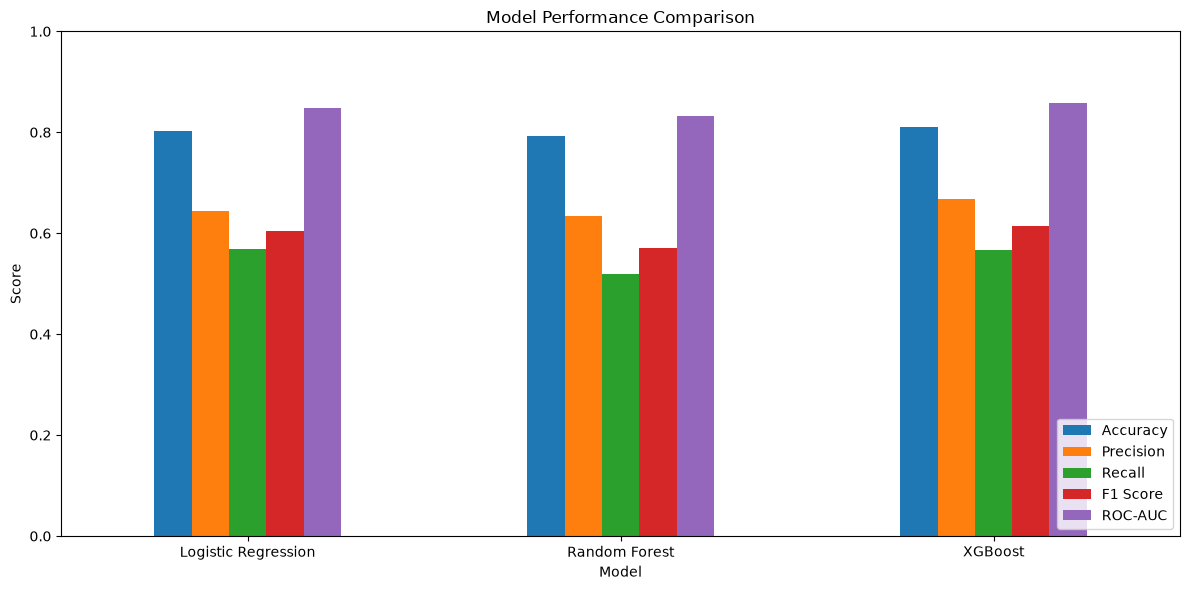

In [29]:
# Model Comparison Plot

metrics = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1 Score",
    "ROC-AUC"
]

model_comparison.set_index("Model")[metrics].plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title("Model Performance Comparison")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

Confusion Matrix:
[[930 105]
 [162 212]]


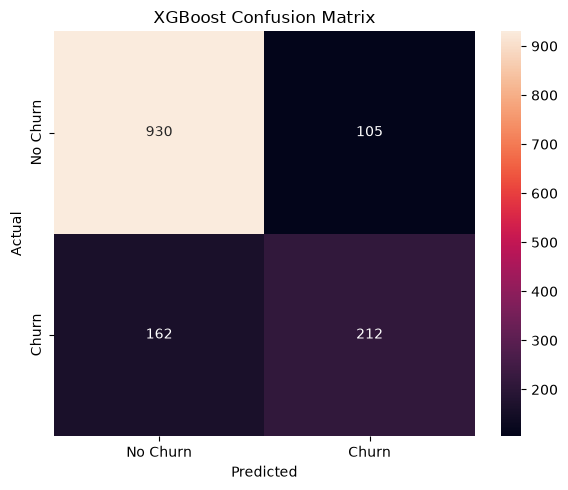

In [30]:
# XGBoost Confusion Matrix

cm = confusion_matrix(
    y_test_encoded,
    xgb_pred
)

print("Confusion Matrix:")
print(cm)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    xticklabels=["No Churn", "Churn"],
    yticklabels=["No Churn", "Churn"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("XGBoost Confusion Matrix")

plt.tight_layout()
plt.show()

In [31]:
# XGBoost Feature Importance

feature_names = (
    numerical_cols +
    encoder.get_feature_names_out(categorical_cols).tolist()
)

feature_importance = pd.DataFrame({
    "Feature": feature_names,
    "Importance": xgb_model.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

feature_importance.head(15)

,Feature,Importance
37,Contract_Month-to-month,0.259162
19,Online Security_No,0.111558
17,Internet Service_Fiber optic,0.086993
10,Dependents_Yes,0.046466
20,Online Security_No internet service,0.044940
16,Internet Service_DSL,0.034009
9,Dependents_No,0.032100
39,Contract_Two year,0.031648
28,Tech Support_No,0.026956
44,Payment Method_Electronic check,0.024290


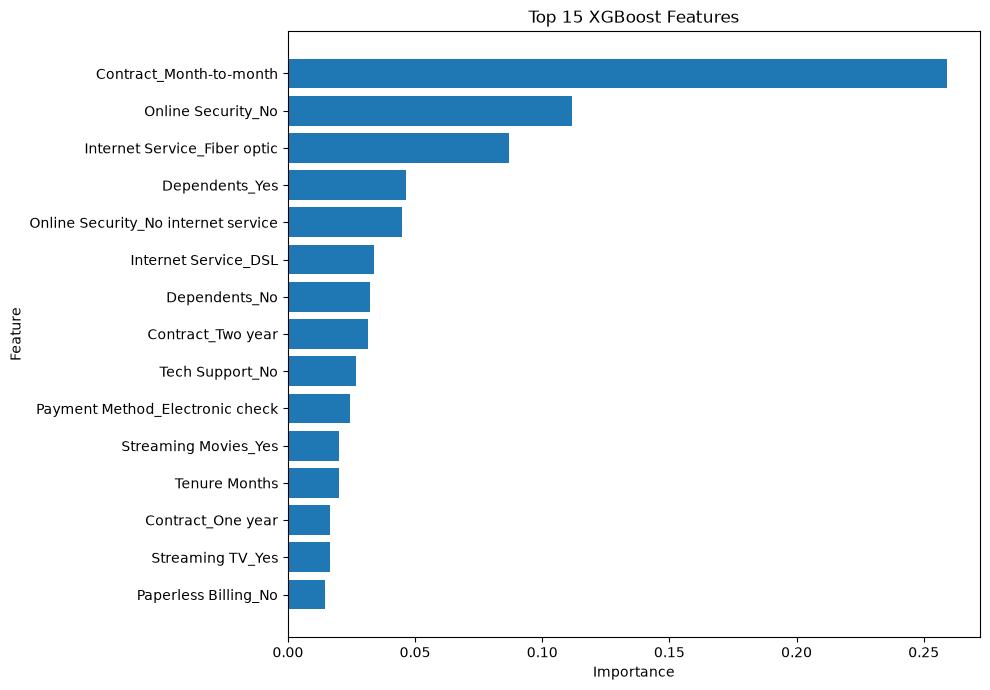

In [32]:
# Top 15 XGBoost Features

top_features = feature_importance.head(15)

plt.figure(figsize=(10, 7))

plt.barh(
    top_features["Feature"][::-1],
    top_features["Importance"][::-1]
)

plt.xlabel("Importance")
plt.ylabel("Feature")
plt.title("Top 15 XGBoost Features")

plt.tight_layout()
plt.show()

In [33]:
# Save Feature Importance

feature_importance.to_csv(
    "../outputs/xgboost_feature_importance.csv",
    index=False
)

print("Feature importance saved successfully!")

Feature importance saved successfully!


In [34]:
# SHAP Analysis

explainer = shap.TreeExplainer(xgb_model)

shap_values = explainer.shap_values(
    X_test_processed
)

print("SHAP analysis completed successfully!")

SHAP analysis completed successfully!


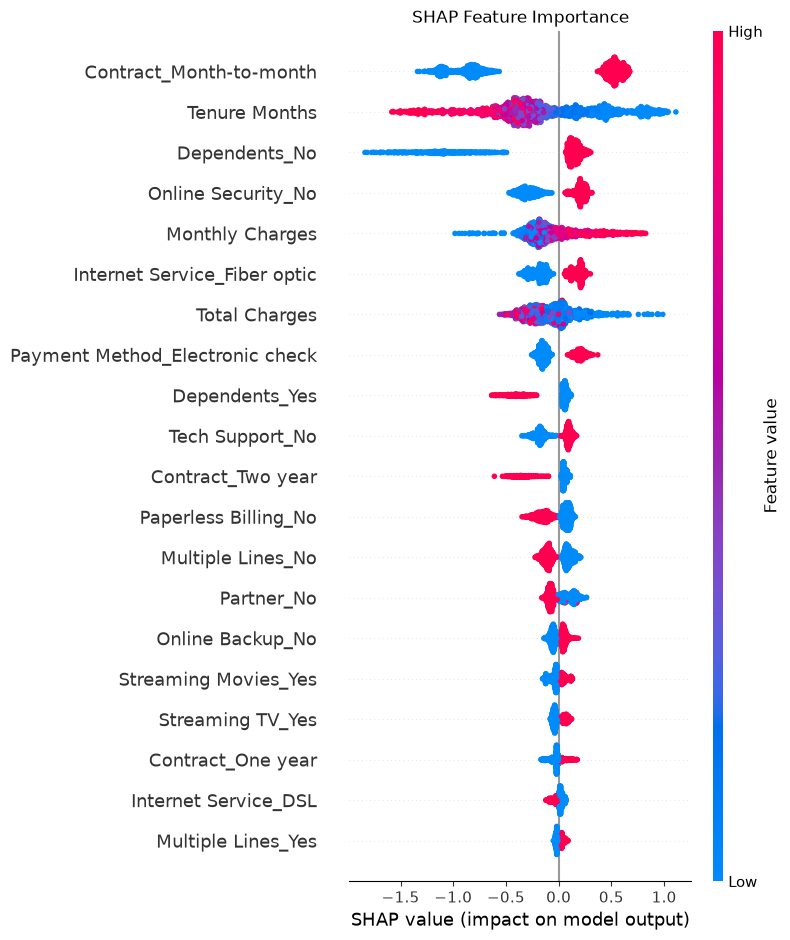

In [35]:
# SHAP Summary Plot

plt.figure()

shap.summary_plot(
    shap_values,
    X_test_processed,
    feature_names=feature_names,
    show=False
)

plt.title("SHAP Feature Importance")

plt.tight_layout()
plt.show()

In [36]:
# Save Model Comparison

model_comparison.to_csv(
    "../outputs/model_comparison.csv",
    index=False
)

print("Model comparison saved successfully!")

Model comparison saved successfully!


In [37]:
# Save Reconstructed Notebook Model

joblib.dump(
    xgb_model,
    "../outputs/notebook_xgboost_model.pkl"
)

joblib.dump(
    encoder,
    "../outputs/notebook_encoder.pkl"
)

joblib.dump(
    scaler,
    "../outputs/notebook_scaler.pkl"
)

joblib.dump(
    numerical_cols,
    "../outputs/notebook_numerical_columns.pkl"
)

joblib.dump(
    categorical_cols,
    "../outputs/notebook_categorical_columns.pkl"
)

print("Notebook model files saved successfully!")

Notebook model files saved successfully!


In [38]:
# Final Project Summary

print("=" * 60)
print("CUSTOMER CHURN PREDICTION - PROJECT SUMMARY")
print("=" * 60)

print("\nDataset:")
print("Total customers:", len(df))

print("\nTarget:")
print("No Churn:", (df["Churn Label"] == "No").sum())
print("Churn:", (df["Churn Label"] == "Yes").sum())

print("\nModels Evaluated:")
print("1. Logistic Regression")
print("2. Random Forest")
print("3. XGBoost")

print("\nXGBoost Results:")
print(f"Accuracy : {xgb_accuracy:.4f}")
print(f"Precision: {xgb_precision:.4f}")
print(f"Recall   : {xgb_recall:.4f}")
print(f"F1 Score : {xgb_f1:.4f}")
print(f"ROC-AUC  : {xgb_roc_auc:.4f}")

print("\nExplainability:")
print("XGBoost Feature Importance")
print("SHAP Analysis")

print("\nDeployment:")
print("Streamlit Web Application")

print("\nProject completed successfully!")
print("=" * 60)

CUSTOMER CHURN PREDICTION - PROJECT SUMMARY

Dataset:
Total customers: 7043

Target:
No Churn: 5174
Churn: 1869

Models Evaluated:
1. Logistic Regression
2. Random Forest
3. XGBoost

XGBoost Results:
Accuracy : 0.8105
Precision: 0.6688
Recall   : 0.5668
F1 Score : 0.6136
ROC-AUC  : 0.8572

Explainability:
XGBoost Feature Importance
SHAP Analysis

Deployment:
Streamlit Web Application

Project completed successfully!
